# Exercise - Multi-Agent Architecture Design

In this exercise, you will design a multi-agent system architecture for a real-world scenario, choosing between orchestrator and peer-to-peer patterns, and implementing the chosen design.

**Challenge**

You're building a multi-agent system for a real-world business process. You need to analyze
the requirements, choose the appropriate architecture pattern, and implement a working prototype that demonstrates your design decisions.

Your solution should:
1. Define a clear business scenario with specific requirements
2. Identify agent roles and responsibilities
3. Choose between orchestrator (supervisor/hierarchical) or peer-to-peer (pipeline/network) patterns
4. Design the data flow and communication protocols
5. Implement a working prototype using LangGraph
6. Create a visual diagram of your architecture


## 0. Set up the notebook

In [7]:
from operator import add
from typing import Annotated, Literal, NotRequired, TypedDict

from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command

## 1. Define Your Business Scenario

**Selected scenario — E-commerce order processing**

An online store needs to decide whether an incoming order is ready for shipment. A valid order has an ID, a product SKU, a positive whole-number quantity, and a supported destination region. The store checks stock and verifies the recorded payment before preparing a shipment plan.

- An invalid order stops at validation.
- An order with insufficient stock stops before payment verification.
- A pending or failed payment stops before shipment planning.
- A valid, in-stock order with a confirmed payment receives a shipment plan.

This prototype uses one order per run, fixed sample stock, and a simulated payment ledger. The shipment plan is a preview and has no external side effects.

## 2. Define Agent Roles and Responsibilities

| Agent | Responsibility | State update |
| --- | --- | --- |
| Supervisor | Choose the next qualified step and record the final outcome. | `outcome` |
| Order validator | Check the order identifiers, quantity, and destination. | `validation` |
| Inventory checker | Compare requested units with sample stock. | `inventory` |
| Payment verifier | Look up the order in the sample payment ledger. | `payment` |
| Fulfillment planner | Prepare the shipment plan after all checks clear. | `shipping_plan` |

The worker agents append their names to `steps`. This trace shows which checks ran and where the supervisor stopped the order.

## 3. Choose Your Architecture Pattern

A) ORCHESTRATOR PATTERN (Supervisor or Hierarchical)
- Use when: You need centralized control, strict workflow order, or complex state management
- Best for: Structured workflows where order matters, complex business processes

B) PEER-TO-PEER PATTERN (Pipeline or Network)
- Use when: You need flexibility, agents can work independently, or dynamic routing
- Best for: Flexible workflows, independent agent operations, dynamic decision-making

**Pattern — Orchestrator with a supervisor**

The order of the checks is a business requirement. A supervisor makes each transition explicit and gives every order a single final outcome. Each worker handles one decision and publishes its result back to the supervisor.

**Communication and data flow**

`START → supervisor → selected worker → supervisor → … → END`

The graph accepts an `OrderInput` and stores results in a typed `OrderState`. Workers read the order and update their assigned fields. The supervisor routes with LangGraph `Command` values. Blocked orders exit at the first failed check.

## 4. Draw Your Multi-Agent System

The graph uses deterministic worker nodes so you can trace each handoff from input to outcome. The diagram uses the Mermaid API to render the compiled graph's nodes and edges.

In [8]:
PaymentStatus = Literal["paid", "pending", "failed"]
OrderOutcome = Literal[
    "ready_to_ship", "invalid_order", "out_of_stock", "payment_pending", "payment_failed",
]


class OrderInput(TypedDict):
    order_id: str
    sku: str
    quantity: int
    region: str


class OrderState(OrderInput):
    validation: NotRequired[Literal["valid", "invalid"]]
    inventory: NotRequired[Literal["available", "unavailable"]]
    payment: NotRequired[PaymentStatus]
    shipping_plan: NotRequired[str]
    outcome: NotRequired[OrderOutcome]
    steps: Annotated[list[str], add]


def supervisor(
    state: OrderState,
) -> Command[Literal["validate_order", "check_inventory", "verify_payment", "plan_shipment", END]]:
    if "validation" not in state:
        return Command(goto="validate_order")
    if state["validation"] == "invalid":
        return Command(goto=END, update={"outcome": "invalid_order"})

    if "inventory" not in state:
        return Command(goto="check_inventory")
    if state["inventory"] == "unavailable":
        return Command(goto=END, update={"outcome": "out_of_stock"})

    if "payment" not in state:
        return Command(goto="verify_payment")
    if state["payment"] == "pending":
        return Command(goto=END, update={"outcome": "payment_pending"})
    if state["payment"] == "failed":
        return Command(goto=END, update={"outcome": "payment_failed"})

    if "shipping_plan" not in state:
        return Command(goto="plan_shipment")
    return Command(goto=END, update={"outcome": "ready_to_ship"})

In [9]:
AVAILABLE_STOCK = {"MUG": 5, "NOTEBOOK": 12}
SUPPORTED_REGIONS = {"US", "CA"}
PAYMENT_LEDGER: dict[str, PaymentStatus] = {
    "ORD-101": "paid",
    "ORD-104": "pending",
    "ORD-105": "failed",
}


def validate_order(state: OrderState) -> dict:
    quantity = state.get("quantity")
    is_valid = (
        bool(state.get("order_id", "").strip())
        and bool(state.get("sku", "").strip())
        and type(quantity) is int
        and quantity > 0
        and state.get("region") in SUPPORTED_REGIONS
    )
    return {
        "validation": "valid" if is_valid else "invalid",
        "steps": ["validate_order"],
    }


def check_inventory(state: OrderState) -> dict:
    has_stock = AVAILABLE_STOCK.get(state["sku"], 0) >= state["quantity"]
    return {
        "inventory": "available" if has_stock else "unavailable",
        "steps": ["check_inventory"],
    }


def verify_payment(state: OrderState) -> dict:
    return {
        "payment": PAYMENT_LEDGER.get(state["order_id"], "pending"),
        "steps": ["verify_payment"],
    }


def plan_shipment(state: OrderState) -> dict:
    return {
        "shipping_plan": f"Standard shipping to {state['region']} for {state['quantity']} × {state['sku']}",
        "steps": ["plan_shipment"],
    }

In [10]:
workflow = StateGraph(OrderState, input_schema=OrderInput)
workflow.add_node("supervisor", supervisor)
workflow.add_edge(START, "supervisor")

workers = [validate_order, check_inventory, verify_payment, plan_shipment]
for worker in workers:
    workflow.add_node(worker.__name__, worker)
    workflow.add_edge(worker.__name__, "supervisor")

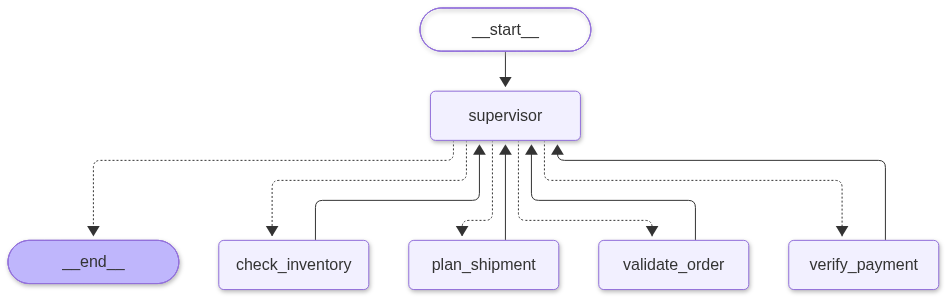

In [11]:
graph = workflow.compile()
diagram_png = graph.get_graph().draw_mermaid_png(draw_method=MermaidDrawMethod.API)
display(Image(data=diagram_png))

## 5. Reflection Questions

1. **Why this pattern?** The store has to validate the order, check stock, and confirm payment in that sequence. The supervisor applies the sequence to every order.
2. **What are the advantages?** Each specialist owns a single check. The supervisor enforces the conditions for shipment planning, and the state trace makes early exits visible.
3. **What challenges could arise?** The supervisor concentrates routing rules as the process grows. In a real store, simultaneous orders also require transactional inventory reservation to prevent overselling.
4. **How would the design adapt?** A delayed payment could pause the order with a checkpoint and resume after a provider event. Inventory reservation and carrier booking would need idempotent operations before they could safely update external systems.

In [12]:
orders = [
    {"order_id": "ORD-101", "sku": "MUG", "quantity": 2, "region": "US"},
    {"order_id": "ORD-102", "sku": "MUG", "quantity": 0, "region": "US"},
    {"order_id": "ORD-103", "sku": "MUG", "quantity": 8, "region": "US"},
    {"order_id": "ORD-104", "sku": "MUG", "quantity": 1, "region": "US"},
    {"order_id": "ORD-105", "sku": "MUG", "quantity": 1, "region": "US"},
]
expected = [
    ("ready_to_ship", ["validate_order", "check_inventory", "verify_payment", "plan_shipment"]),
    ("invalid_order", ["validate_order"]),
    ("out_of_stock", ["validate_order", "check_inventory"]),
    ("payment_pending", ["validate_order", "check_inventory", "verify_payment"]),
    ("payment_failed", ["validate_order", "check_inventory", "verify_payment"]),
]

for order, (expected_outcome, expected_steps) in zip(orders, expected, strict=True):
    result = graph.invoke(order)
    assert result["order_id"] == order["order_id"]
    assert result["outcome"] == expected_outcome, result
    assert result["steps"] == expected_steps, result
    assert bool(result.get("shipping_plan")) == (expected_outcome == "ready_to_ship")
    print(f"{result['order_id']} | {result['outcome']} | {' → '.join(result['steps'])}")

print(f"Passed {len(orders)} order scenarios.")

ORD-101 | ready_to_ship | validate_order → check_inventory → verify_payment → plan_shipment
ORD-102 | invalid_order | validate_order
ORD-103 | out_of_stock | validate_order → check_inventory
ORD-104 | payment_pending | validate_order → check_inventory → verify_payment
ORD-105 | payment_failed | validate_order → check_inventory → verify_payment
Passed 5 order scenarios.
